In [31]:
import numpy as np
import numpy.linalg as la
import pandas as pd
import imageio.v3 as iio
import scipy.ndimage as img
import matplotlib.pyplot as plt
import scipy.optimize as opt
#import mygrad as mg

# Problem 2.1: setting the stage

## Task 2.1.1

In [32]:
def load_myspace_data():
    df = pd.read_csv('dataMyspace201303.csv')

    second = np.array(df.iloc[:, 1])

    searchCount = np.trim_zeros(second, 'f')

    time = np.array(np.linspace(1, len(searchCount), len(searchCount))).T

    return time, searchCount

In [33]:
def plot_myspace_data(x, y):
    plt.figure()
    plt.plot(x, y, label='datapoints')
        
    plt.xlabel('week after onset')
    plt.ylabel('normalized search count')
    plt.legend()
    plt.show()

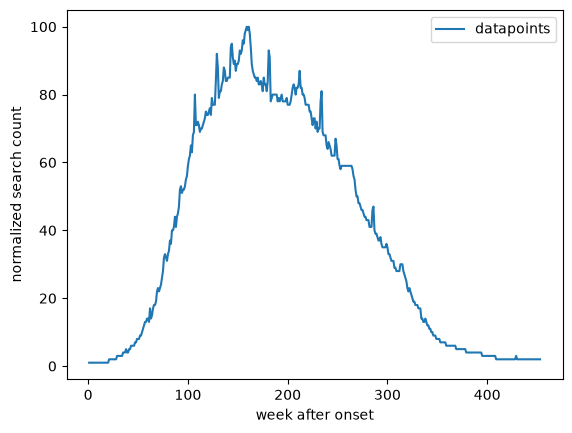

In [34]:
x, y = load_myspace_data()
plot_myspace_data(x, y)

## Task 2.1.2

In [35]:
def weibull_pdf(t, a, b):
    return (a/b) * (t/b)**(a-1) * np.exp(-((t/b)**a))

def weibull_cdf(t, a, b):
    return 1 - np.exp(-((t/b)**a))

Weibull PDF; beta = 2.0 | ==============================


/tmp/ipykernel_12279/859702572.py:2: RuntimeWarning: divide by zero encountered in power
  return (a/b) * (t/b)**(a-1) * np.exp(-((t/b)**a))


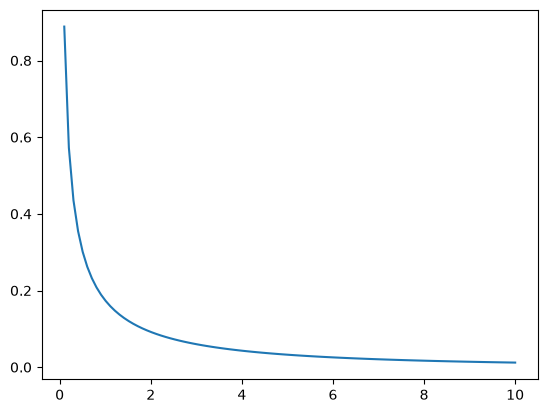

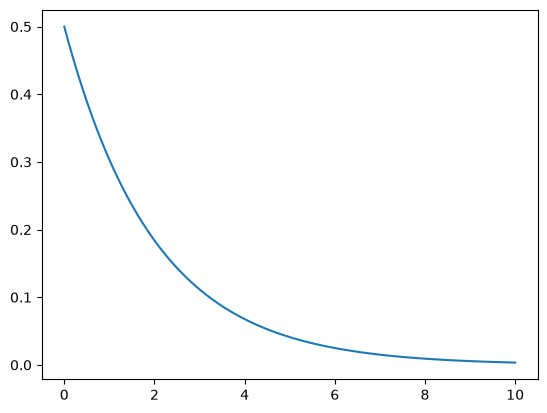

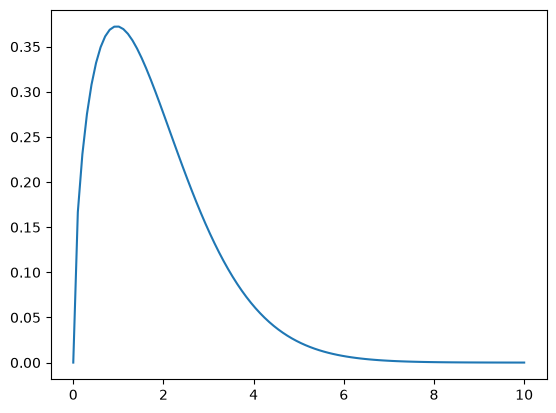

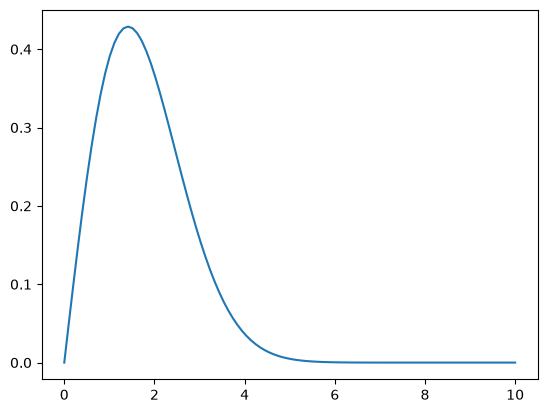

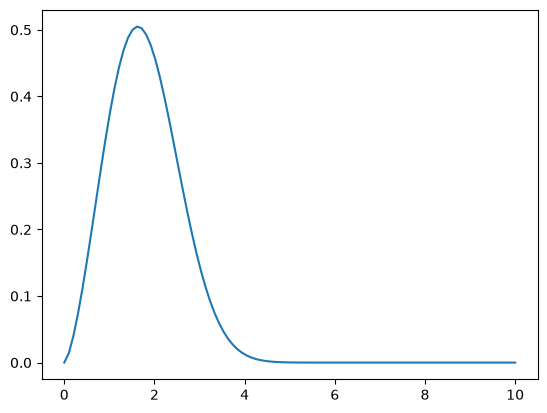

Weibull PDF; alpha = 2.5 | =============================


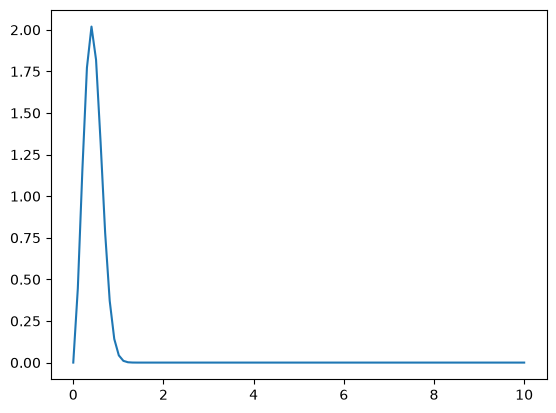

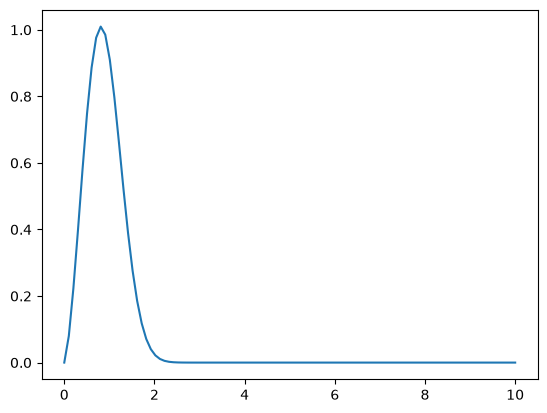

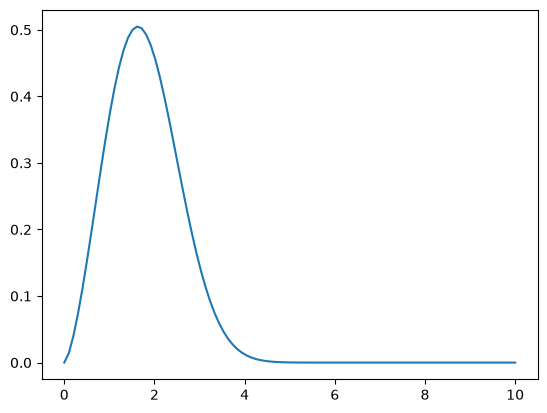

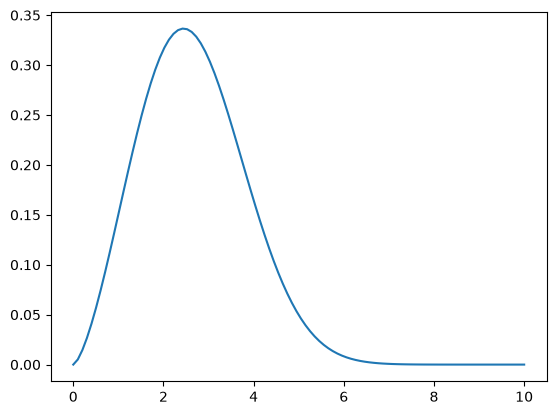

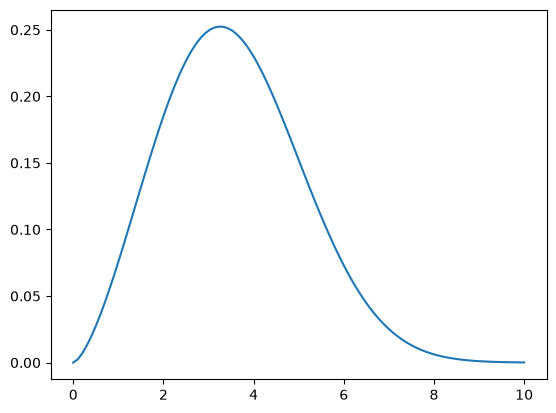

In [36]:
ts = np.linspace(0, 10, 100)
print('Weibull PDF; beta = 2.0 | ==============================')
for alpha in [0.5, 1.0, 1.5, 2.0, 2.5]:
    plt.plot(ts, weibull_pdf(ts, alpha, 2.0), '-')
    plt.show()

print('Weibull PDF; alpha = 2.5 | =============================')
for beta in [0.5, 1, 2, 3, 4]:
    plt.plot(ts, weibull_pdf(ts, 2.5, beta),  '-')
    plt.show()

# Problem 2.2: fitting a Weibull to a histogram (part 1)


## Task 2.2.1

In [37]:
def loss(a,b,D):
    N = len(D)
    return N * (np.log(a) - a*np.log(b)) + (a-1) * np.sum(np.log(D)) - np.sum((D/b)**a)

def dLa(a,b,D):
    N = len(D)
    return N/a - N*np.log(b) + np.sum(np.log(D)) - np.sum((D/b)**a * np.log(D/b))

def dLb(a,b,D):
    N = len(D)
    return a/b * (np.sum((D/b)**a)-N)

def dLa2(a,b,D):
    N = len(D)
    return -(N/(a*a)) - np.sum((D/b)**a * (np.log(D/b)**2))

def dLb2(a,b,D):
    N = len(D)
    return (a/(b*b)) * (N-(a+1)*np.sum((D/b)**a))

def dLab(a,b,D):
    N = len(D)
    return (1/b) * np.sum((D/b)**a) + (a/b) * np.sum((D/b)**a * np.log(D/b)) - N/b

In [38]:
def newtonIncrement(a,b,D):
    dla  = dLa(a,b,D)
    dlb  = dLb(a,b,D)
    dla2 = dLa2(a,b,D)
    dlb2 = dLb2(a,b,D)
    dlab = dLab(a,b,D)

    mat1 = np.array([a,b]).T
    mat2 = np.linalg.inv(np.array([[dla2, dlab],[dlab, dlb2]]))
    mat3 = np.array([dla, dlb]).T

    return mat1 - mat2 @ mat3

def newtonUpdate(iterations):
    a = 1
    b = 1
    t, c = load_myspace_data()
    D = np.repeat(t,c) # non-elegant way

    for i in range(iterations):
        result = newtonIncrement(a,b,D)
        a = result[0]
        b = result[1]

    print(f'values after {iterations} iterations: \nalpha: {a} | beta: {b}')
    return a,b

## Task 2.2.2

In [39]:
def plot_weibull_fitted(x,y, a,b):
    plt.figure()
    plt.plot(x, y, label='datapoints')
    
    scale = np.max(y) / np.max(weibull_pdf(x,a,b))
    plt.plot(x, scale * weibull_pdf(x,a,b), label ='fitted weibull')
        
    plt.xlabel('week after onset')
    plt.ylabel('normalized search count')
    plt.legend()
    plt.show()

values after 20 iterations: 
alpha: 2.808560133416446 | beta: 215.42856990275794


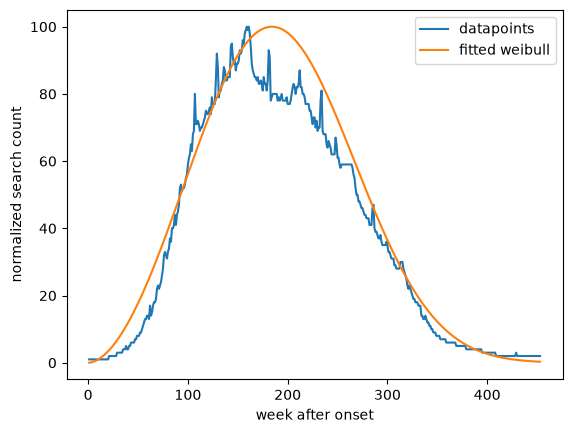

In [40]:
t,c = load_myspace_data()
a,b = newtonUpdate(20)
plot_weibull_fitted(t,c,a,b)

# Problem 2.3: fitting a Weibull to a histogram (part 2)

## Task 2.3.1

In [41]:
def f_tilde(x,A,a,b):
    return A * weibull_pdf(x,a,b)

def optimizeParamsScipy(fun, t,c, A,a,b):
    popt, _ = opt.curve_fit(fun, t, c, p0=[A,a,b], bounds=([0,0,0],[np.inf, np.inf, np.inf]))
    A_opt, a_opt, b_opt = popt
    print(f'values after scipy curve_fit: \nalpha: {a_opt} | beta: {b_opt}')
    return A_opt, a_opt, b_opt

## Task 2.3.2

In [42]:
def plot_weibull_weighed(t,c,A,a,b):
    plt.figure()
    plt.plot(t, c, label='datapoints')
    plt.plot(t, f_tilde(t,A,a,b), label ='scaled weibull')
        
    plt.xlabel('week after onset')
    plt.ylabel('normalized search count')
    plt.legend()
    plt.show()

values after scipy curve_fit: 
alpha: 2.730954980105152 | beta: 211.02437701263128


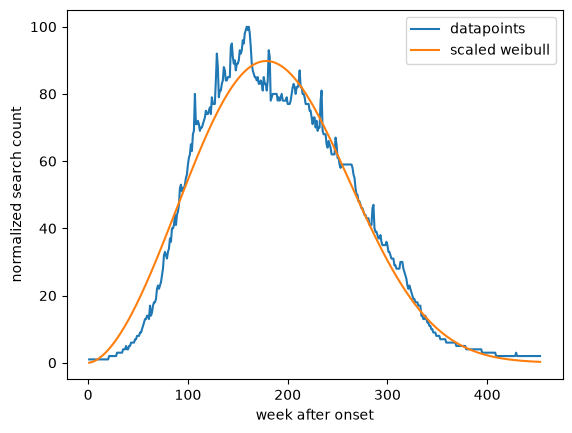

In [43]:
t, c = load_myspace_data()

A_opt, a_opt, b_opt = optimizeParamsScipy(f_tilde, t,c, 1000,2,200)
plot_weibull_weighed(t,c,A_opt,a_opt,b_opt)

# Problem 2.4: fitting a Weibull to a histogram (part 3)

## Task 2.4.1

In [62]:
def residual(theta,t,c):
    a,b = theta
    w = 1/p(t,a,b)
    return np.sqrt(w) * (c - np.sum(c)*p(t, a,b)) 

def p(t, a,b):
    # F(t) - F(t-1)
    return weibull_cdf(t, a,b) - weibull_cdf(t-1, a,b)

In [63]:
t,c = load_myspace_data()
res = opt.least_squares(residual, x0=[2,200], args=(t,c), bounds=([0,0], [np.inf,np.inf]))
a_opt, b_opt = res.x

print(f'values after scipy least_squares opt: \nalpha: {a_opt} | beta: {b_opt}')

values after scipy least_squares opt: 
alpha: 2.645935178360951 | beta: 213.45426452552823


## Task 2.4.2

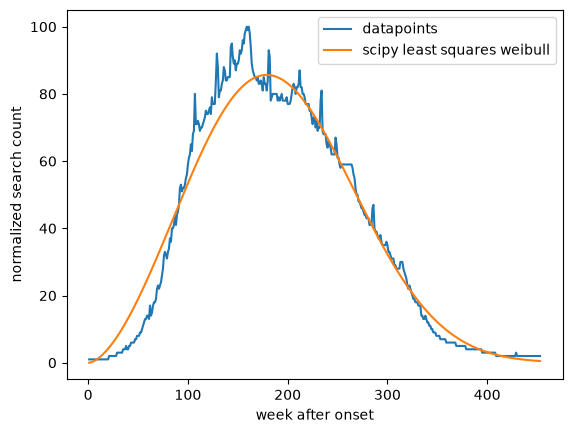

In [72]:
plt.figure()
plt.plot(t, c, label='datapoints')
plt.plot(t, np.sum(c)* p(t,a_opt,b_opt), label ='scipy least squares weibull')
    
plt.xlabel('week after onset')
plt.ylabel('normalized search count')
plt.legend()
plt.show()